# Tarea 1 – Parte 2: Del LLM al clasificador

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

Este notebook parte de `datos/noticias.csv` (Parte 1). La etiqueta de referencia (`etiqueta`) es la sección del diario mapeada a las 4 categorías oficiales. Sobre ella se comparan tres enfoques:

| Paso | Enfoque | Modelo |
| :--- | :--- | :--- |
| 1 | Línea base zero-shot (sin entrenamiento) | `Recognai/bert-base-spanish-wwm-cased-xnli` |
| 2 | Supervisión débil con LLM local | `Qwen2.5-1.5B-Instruct` (GGUF 4 bits, `llama.cpp`) |
| 3–5 | Transformer con fine-tuning | `distilbert/distilbert-base-multilingual-cased` |
| 6 | Comparativa y decisión | — |

**Equipo usado:** laptop con Windows, **solo CPU** y **7.3 GB de RAM**. Esta restricción explica varias decisiones técnicas (formato del LLM, embeddings congelados en el fine-tuning) que se documentan en cada sección.

In [1]:
import gc
import json
import time
import warnings
from datetime import date
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import seaborn as sns
from datasets import Dataset
from huggingface_hub import hf_hub_download
from llama_cpp import Llama
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments, pipeline, set_seed)
import datasets
import huggingface_hub
import transformers

# Salida limpia: sin barras de progreso de carga/guardado. Se silencia también un aviso de transformers 5
# sobre un "regex incorrecto" en el tokenizador: es un falso positivo para DistilBERT, que usa
# BertPreTokenizer + WordPiece (verificado: "dólar" -> ["dó", "##lar"]).
transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()
datasets.disable_progress_bars()
huggingface_hub.utils.disable_progress_bars()

pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width = 900
pio.renderers["png"].height = 480
pd.set_option("display.max_colwidth", 110)

SEMILLA = 42
set_seed(SEMILLA)
DATOS, RAW, MODELO = Path("datos"), Path("datos/raw"), Path("modelo")
ETIQUETAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]

df = pd.read_csv(DATOS / "noticias.csv").fillna({"bajada": ""})
print("Fecha de ejecución:", date.today().isoformat(), "| df.shape:", df.shape)
df["etiqueta"].value_counts().reindex(ETIQUETAS).rename("noticias")

Fecha de ejecución: 2026-10-18 | df.shape: (374, 7)


etiqueta
politica              91
economia              90
deportes              98
ciencia_tecnologia    95
Name: noticias, dtype: int64

In [2]:
def metricas(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, labels=ETIQUETAS, average="macro", zero_division=0),
    }

## 1. Línea base zero-shot (sin fine-tuning)

Se evalúan **40 titulares** (10 por categoría, muestreo estratificado con `random_state=42`) con `pipeline("zero-shot-classification")` y el modelo NLI en español `Recognai/bert-base-spanish-wwm-cased-xnli`.

El modelo no conoce las categorías: para cada titular evalúa si la hipótesis *"Esta noticia trata sobre {categoría}."* se desprende del texto. Se usan los nombres naturales en español (`política`, `economía`, `deportes`, `ciencia y tecnología`) y luego se mapean a las etiquetas oficiales. El F1 macro obtenido es el **piso mínimo** que deben superar los otros enfoques.

In [3]:
ZS_MODELO = "Recognai/bert-base-spanish-wwm-cased-xnli"
ZS_ETIQUETAS = {"política": "politica", "economía": "economia",
                "deportes": "deportes", "ciencia y tecnología": "ciencia_tecnologia"}
zs = pipeline("zero-shot-classification", model=ZS_MODELO, device=-1)

def zero_shot(titulares):
    salida = zs(list(titulares), candidate_labels=list(ZS_ETIQUETAS),
                hypothesis_template="Esta noticia trata sobre {}.")
    return [ZS_ETIQUETAS[s["labels"][0]] for s in salida]

muestra_zs = df.groupby("etiqueta", group_keys=False).sample(n=10, random_state=SEMILLA).copy()
t0 = time.time()
muestra_zs["pred_zs"] = zero_shot(muestra_zs["titular"])
lat_zs = (time.time() - t0) / len(muestra_zs)
m_zs40 = metricas(muestra_zs["etiqueta"], muestra_zs["pred_zs"])
print(f"Zero-shot en 40 titulares -> accuracy {m_zs40['accuracy']:.3f} | F1 macro {m_zs40['f1_macro']:.3f} "
      f"| {lat_zs * 1000:.0f} ms por titular")
pd.crosstab(muestra_zs["etiqueta"], muestra_zs["pred_zs"], rownames=["real"], colnames=["zero-shot"])

Zero-shot en 40 titulares -> accuracy 0.600 | F1 macro 0.579 | 303 ms por titular


zero-shot,ciencia_tecnologia,deportes,economia,politica
real,,,,
ciencia_tecnologia,4,2,1,3
deportes,0,10,0,0
economia,1,0,3,6
politica,0,1,2,7


In [4]:
# Se libera memoria: el modelo zero-shot se vuelve a cargar en la comparativa final
del zs
gc.collect();

## 2. Supervisión débil con un LLM local

**Modelo:** `Qwen2.5-1.5B-Instruct`, en la versión GGUF oficial de Qwen cuantizada a 4 bits (`Q4_K_M`, ~1.1 GB), ejecutada con `llama.cpp` (`llama-cpp-python`).

**¿Por qué GGUF y no la versión de `transformers`?** Primero se probó la versión estándar en la laptop:

- En `float32` necesita ~6 GB de RAM, y el equipo solo tiene 7.3 GB en total.
- En `bfloat16` tardó **10–14 s por titular** (la CPU no acelera ese formato), lo que equivale a más de 1 hora para el dataset.
- La cuantización dinámica int8 de PyTorch lo volvía incapaz de seguir la instrucción.

La versión GGUF de 4 bits mantiene la calidad del modelo y cabe holgadamente en memoria.

**Prompt estructurado** (formato de chat ChatML de Qwen):

- **Sistema:** define las 4 categorías con ejemplos de temas y pide responder solo con el nombre de la categoría.
- **6 ejemplos *few-shot* inventados** (no salen del dataset, para no filtrar información de test): muestran el formato titular + bajada → categoría.
- **Usuario:** el titular y la bajada de la noticia a clasificar.

**Etiqueta y confianza:** en lugar de generar texto libre, se calcula la probabilidad que el LLM asigna a cada respuesta posible:

- Se suman las variantes de escritura de cada categoría (con y sin tilde o mayúscula, por ejemplo `política` y `Política`).
- Se normaliza entre las 4 categorías.
- `etiqueta_llm` es la de mayor probabilidad, así que el LLM no puede inventar una quinta categoría.
- `confianza` es esa probabilidad normalizada.

**Ajuste del prompt antes de etiquetar** (con 40 noticias de prueba, `random_state=7`):

| Variante | Acierto vs. sección |
| :--- | :---: |
| Solo instrucciones, etiqueta exacta sin tilde | 62 % (sesgo fuerte hacia `politica`) |
| Few-shot + respuesta numérica (1–4) | 85 % |
| **Few-shot + nombres con variantes (elegida)** | **90 %** |

Cada respuesta se respalda en `datos/raw/llm_respuestas.jsonl`, así que al reejecutar el notebook no se recalcula lo ya etiquetado. En `etiquetas_llm.csv`, la columna `fecha` es la fecha del etiquetado.

In [5]:
LLM_REPO, LLM_ARCHIVO = "Qwen/Qwen2.5-1.5B-Instruct-GGUF", "qwen2.5-1.5b-instruct-q4_k_m.gguf"
MODELO_LLM = "Qwen2.5-1.5B-Instruct-GGUF-Q4_K_M"

SISTEMA = '''Eres editor de un diario peruano. Clasifica cada noticia en una de estas 4 categorías:
- política: gobierno, Congreso, Senado, elecciones, partidos, ministros, fiscalía y justicia sobre autoridades.
- economía: dólar, mercados, empresas, inversión, empleo, impuestos, precios, bancos, comercio.
- deportes: fútbol, clubes, partidos, goles, vóley, tenis, automovilismo, atletas y competencias.
- ciencia y tecnología: tecnología, empresas tecnológicas, internet, inteligencia artificial, celulares, videojuegos, salud y medicina, ciencia, espacio, animales, medio ambiente.
Responde solo con el nombre de la categoría.'''

RESPUESTA = {"politica": "política", "economia": "economía", "deportes": "deportes",
             "ciencia_tecnologia": "ciencia y tecnología"}
VARIANTES = {
    "politica": ["política", "Política", "politica", "Politica"],
    "economia": ["economía", "Economía", "economia", "Economia"],
    "deportes": ["deportes", "Deportes"],
    "ciencia_tecnologia": ["ciencia y tecnología", "Ciencia y tecnología", "Ciencia y Tecnología",
                           "tecnología", "Tecnología"],
}
# Ejemplos few-shot inventados (no pertenecen al dataset)
EJEMPLOS = [
    ("Premier se presenta ante el pleno para pedir el voto de confianza",
     "El gabinete expuso su plan de gobierno ante el Congreso.", "politica"),
    ("Selección peruana convoca a tres juveniles para la fecha FIFA",
     "El técnico anunció la lista de convocados para los amistosos.", "deportes"),
    ("Apple presenta un nuevo chip para sus computadoras con IA",
     "La compañía promete el doble de velocidad y mejor batería.", "ciencia_tecnologia"),
    ("BCRP mantiene su tasa de referencia en 4.25%", "La inflación se ubicó dentro del rango meta.", "economia"),
    ("Científicos descubren una nueva especie de rana en la Amazonía",
     "El hallazgo fue publicado en una revista internacional.", "ciencia_tecnologia"),
    ("Alianza Lima empató 1-1 con Melgar en Matute",
     "Los íntimos no pudieron sostener la ventaja en el Torneo Clausura.", "deportes"),
]

def turno_usuario(titular, bajada):
    return f"<|im_start|>user\nTitular: {titular}\nBajada: {bajada}<|im_end|>\n<|im_start|>assistant\n"

# Plantilla de chat ChatML de Qwen: sistema + ejemplos few-shot (prefijo común a todas las noticias)
PREFIJO = f"<|im_start|>system\n{SISTEMA}<|im_end|>\n"
for t, b, e in EJEMPLOS:
    PREFIJO += turno_usuario(t, b) + RESPUESTA[e] + "<|im_end|>\n"
print(PREFIJO + turno_usuario("<titular>", "<bajada>"))

<|im_start|>system
Eres editor de un diario peruano. Clasifica cada noticia en una de estas 4 categorías:
- política: gobierno, Congreso, Senado, elecciones, partidos, ministros, fiscalía y justicia sobre autoridades.
- economía: dólar, mercados, empresas, inversión, empleo, impuestos, precios, bancos, comercio.
- deportes: fútbol, clubes, partidos, goles, vóley, tenis, automovilismo, atletas y competencias.
- ciencia y tecnología: tecnología, empresas tecnológicas, internet, inteligencia artificial, celulares, videojuegos, salud y medicina, ciencia, espacio, animales, medio ambiente.
Responde solo con el nombre de la categoría.<|im_end|>
<|im_start|>user
Titular: Premier se presenta ante el pleno para pedir el voto de confianza
Bajada: El gabinete expuso su plan de gobierno ante el Congreso.<|im_end|>
<|im_start|>assistant
política<|im_end|>
<|im_start|>user
Titular: Selección peruana convoca a tres juveniles para la fecha FIFA
Bajada: El técnico anunció la lista de convocados para lo

In [6]:
llm = Llama(model_path=hf_hub_download(LLM_REPO, LLM_ARCHIVO), n_ctx=2048, n_threads=6,
            seed=SEMILLA, verbose=False)
tokens = lambda texto, especial: llm.tokenize(texto.encode("utf-8"), add_bos=False, special=especial)
SECUENCIAS = {e: [tokens(v, False) for v in vs] for e, vs in VARIANTES.items()}

def ultimos_logits():
    return np.ctypeslib.as_array(llm._ctx.get_logits(), shape=(llm.n_vocab(),)).astype(np.float64)

def log_softmax(v):
    m = v.max()
    return v - (m + np.log(np.exp(v - m).sum()))

# El prefijo (sistema + few-shot) se procesa una sola vez. Para cada noticia se "rebobina" la caché KV
# hasta el final del prefijo: eval() descarta todo lo posterior a llm.n_tokens.
llm.reset()
llm.eval(tokens(PREFIJO, True))
N_PREFIJO = llm.n_tokens

def clasificar_llm(titular, bajada):
    llm.n_tokens = N_PREFIJO
    llm.eval(tokens(turno_usuario(titular, bajada), True))
    n_noticia = llm.n_tokens
    lp_inicial = log_softmax(ultimos_logits())
    prob = {}
    for etiqueta, variantes in SECUENCIAS.items():
        total = 0.0
        for seq in variantes:            # P(respuesta completa | prompt), token a token
            lp = lp_inicial[seq[0]]
            if len(seq) > 1:
                llm.n_tokens = n_noticia
                for i in range(1, len(seq)):
                    llm.eval([seq[i - 1]])
                    lp += log_softmax(ultimos_logits())[seq[i]]
            total += np.exp(lp)
        prob[etiqueta] = total
    p = pd.Series(prob) / sum(prob.values())
    return p.idxmax(), float(p.max())

print(clasificar_llm("Congreso aprueba nuevo retiro de fondos de AFP",
                     "La medida beneficiará a más de 4 millones de afiliados."))

llama_new_context_with_model: n_ctx_per_seq (2048) < n_ctx_train (32768) -- the full capacity of the model will not be utilized


('politica', 0.8419195425190302)


In [7]:
RESPALDO_LLM = RAW / "llm_respuestas.jsonl"
hechas = {}
if RESPALDO_LLM.exists():
    for linea in RESPALDO_LLM.read_text(encoding="utf-8").splitlines():
        d = json.loads(linea)
        hechas[d["url"]] = d

pendientes = df[~df["url"].isin(hechas)]
print(f"Ya etiquetadas: {len(hechas)} | por etiquetar: {len(pendientes)}")
t0 = time.time()
with RESPALDO_LLM.open("a", encoding="utf-8") as f:
    for i, fila in enumerate(pendientes.itertuples(), 1):
        etiqueta, confianza = clasificar_llm(fila.titular, fila.bajada)
        d = {"url": fila.url, "etiqueta_llm": etiqueta, "confianza": round(confianza, 4),
             "fecha": date.today().isoformat()}
        f.write(json.dumps(d, ensure_ascii=False) + "\n")
        hechas[fila.url] = d
        if i % 50 == 0:
            print(f"  {i}/{len(pendientes)} ({time.time() - t0:.0f}s)")
if len(pendientes):
    lat_llm = (time.time() - t0) / len(pendientes)
    (RAW / "llm_latencia.json").write_text(json.dumps({"segundos_por_noticia": lat_llm}), encoding="utf-8")
lat_llm = json.loads((RAW / "llm_latencia.json").read_text(encoding="utf-8"))["segundos_por_noticia"]
print(f"Latencia del LLM: {lat_llm:.2f} s por noticia en CPU")

del llm
gc.collect();

Ya etiquetadas: 374 | por etiquetar: 0
Latencia del LLM: 2.70 s por noticia en CPU


In [8]:
etiquetas_llm = df[["url", "titular"]].assign(
    etiqueta_llm=df["url"].map(lambda u: hechas[u]["etiqueta_llm"]),
    confianza=df["url"].map(lambda u: hechas[u]["confianza"]),
    modelo_llm=MODELO_LLM,
    fecha=df["url"].map(lambda u: hechas[u]["fecha"]),
)
etiquetas_llm = etiquetas_llm[["titular", "etiqueta_llm", "confianza", "modelo_llm", "fecha", "url"]]
etiquetas_llm.to_csv(DATOS / "etiquetas_llm.csv", index=False, encoding="utf-8")
print("Guardado datos/etiquetas_llm.csv", etiquetas_llm.shape)
etiquetas_llm.head()

Guardado datos/etiquetas_llm.csv (374, 6)


,titular,etiqueta_llm,confianza,modelo_llm,fecha,url
0,Tesla presenta un Roadster capaz de ‘volar’ y en las redes sociales lo reciben con memes,ciencia_tecnologia,0.9838,Qwen2.5-1.5B-Instruct-GGUF-Q4_K_M,2026-10-18,https://elcomercio.pe/tecnologia/actualidad/tesla-presenta-un-roadster-capaz-de-volar-y-en-las-redes-socia...
1,Alemania investiga una presunta agresión sexual con un robot contra joven de 16 años,politica,0.8547,Qwen2.5-1.5B-Instruct-GGUF-Q4_K_M,2026-10-18,https://elcomercio.pe/tecnologia/robotica/alemania-investiga-una-presunta-agresion-sexual-con-un-robot-con...
2,Intel en Latinoamérica: “Los gobiernos deben crear condiciones o reglas para un uso saludable de la IA”,ciencia_tecnologia,0.9994,Qwen2.5-1.5B-Instruct-GGUF-Q4_K_M,2026-10-18,https://elcomercio.pe/tecnologia/actualidad/intel-en-latinoamerica-los-gobiernos-deben-crear-condiciones-o...
3,Padre de la IA y otros 224 científicos piden “cambios inmediatos” para su desarrollo y despliegue,ciencia_tecnologia,0.9999,Qwen2.5-1.5B-Instruct-GGUF-Q4_K_M,2026-10-18,https://elcomercio.pe/tecnologia/inteligencia-artificial/padre-de-la-ia-y-otros-224-cientificos-piden-camb...
4,Descubren en los Andes peruanos una nueva flor y la bautizan en honor a Lionel Messi,ciencia_tecnologia,0.9996,Qwen2.5-1.5B-Instruct-GGUF-Q4_K_M,2026-10-18,https://elcomercio.pe/tecnologia/ciencias/salvia-messii-descubren-en-los-andes-peruanos-una-nueva-flor-y-l...


### 2.1 ¿Cuánto coincide el LLM con la sección del diario?

In [9]:
df["etiqueta_llm"] = etiquetas_llm["etiqueta_llm"].values
df["confianza_llm"] = etiquetas_llm["confianza"].values
m_llm_total = metricas(df["etiqueta"], df["etiqueta_llm"])
print(f"LLM vs. sección (dataset completo, {len(df)} noticias) -> accuracy {m_llm_total['accuracy']:.3f} "
      f"| F1 macro {m_llm_total['f1_macro']:.3f}")

alta = df["confianza_llm"] >= 0.9
print(f"Con confianza >= 0.90 ({alta.mean():.0%} de las noticias): accuracy "
      f"{(df.loc[alta, 'etiqueta'] == df.loc[alta, 'etiqueta_llm']).mean():.3f}; con confianza < 0.90: "
      f"{(df.loc[~alta, 'etiqueta'] == df.loc[~alta, 'etiqueta_llm']).mean():.3f}")
pd.crosstab(df["etiqueta"], df["etiqueta_llm"], rownames=["sección"], colnames=["LLM"])

LLM vs. sección (dataset completo, 374 noticias) -> accuracy 0.872 | F1 macro 0.867
Con confianza >= 0.90 (78% de las noticias): accuracy 0.935; con confianza < 0.90: 0.646


LLM,ciencia_tecnologia,deportes,economia,politica
sección,,,,
ciencia_tecnologia,84,2,2,7
deportes,2,91,0,5
economia,19,1,60,10
politica,0,0,0,91


### 2.2 Auditoría humana de 20 predicciones al azar

Se toman 20 noticias al azar (`df.sample(n=20, random_state=42)`). La estudiante las clasificó **a ciegas**: solo con el titular y la bajada, sin ver la etiqueta del LLM ni la sección del diario.

Sus etiquetas están en `datos/auditoria_humana.csv` (columna `etiqueta_humana`) y aquí se cruzan con las del LLM. El acuerdo es la proporción de casos en que ambas coinciden.

In [10]:
AUDITORIA = DATOS / "auditoria_humana.csv"
if not AUDITORIA.exists():
    # Plantilla para la revisión manual a ciegas: no incluye la etiqueta del LLM ni la sección
    (df.sample(n=20, random_state=SEMILLA)[["url", "titular", "bajada"]]
       .assign(etiqueta_humana="", comentario="")
       .to_csv(AUDITORIA, index=False, encoding="utf-8"))
aud = (pd.read_csv(AUDITORIA).fillna("")
         .merge(df[["url", "etiqueta_llm", "confianza_llm", "etiqueta"]], on="url", how="left"))

if (aud["etiqueta_humana"] != "").all():
    aud["coincide"] = aud["etiqueta_humana"] == aud["etiqueta_llm"]
    acuerdo = int(aud["coincide"].sum())
    print(f"Acuerdo LLM-humano: {acuerdo}/20 = {acuerdo / 20:.0%}")
    print(f"(Como referencia, humano vs. sección del diario: {(aud['etiqueta_humana'] == aud['etiqueta']).sum()}/20)")
else:
    acuerdo = None
    print("Auditoría pendiente: completar la columna etiqueta_humana en", AUDITORIA)
aud[["titular", "etiqueta_humana", "etiqueta_llm", "confianza_llm"] + (["coincide"] if acuerdo is not None else [])]

Acuerdo LLM-humano: 17/20 = 85%
(Como referencia, humano vs. sección del diario: 19/20)


,titular,etiqueta_humana,etiqueta_llm,confianza_llm,coincide
0,Keiko Fujimori ratifica su respaldo al ministro César Astudillo y al jefe de la PNP Fredy López,politica,politica,0.9983,True
1,"Maia 300, el nuevo chip de Microsoft para escalar su infraestructura de IA que llegará en 2027",ciencia_tecnologia,ciencia_tecnologia,1.0000,True
2,"Efecto cine, batería de emergencia o verificación: cinco novedades del iPhone 18",ciencia_tecnologia,ciencia_tecnologia,0.9992,True
3,"Ley MAPE: Minem prevé presentar propuesta este jueves, ¿qué plantea y qué advierten los expertos sobre el ...",politica,politica,0.8274,True
4,Así es Midnight Mimosa: el ‘malware’ preinstalado en móviles Android de bajo coste que roba datos y usa ‘a...,ciencia_tecnologia,ciencia_tecnologia,0.9989,True
5,"Aranwa Hotels: Por qué la gastronomía ya representa hasta 48% de sus ingresos, sus proyectos en Costa Rica...",economia,ciencia_tecnologia,0.6937,False
6,¿Qué es la homoquiralidad que ha protagonizado el Nobel de Química?,ciencia_tecnologia,ciencia_tecnologia,0.9999,True
7,Luis Iberico marcó el 1-0 de Sporting Cristal vs. Comerciantes Unidos por el Torneo Clausura | VIDEO,deportes,deportes,0.9997,True
8,¿Quiénes son los congresistas que viajaron a China durante la semana de representación y cuál es su agenda?,politica,politica,0.9997,True
9,"Franco Navarro Mandayo: “En el Clausura de Alianza, hay 7 u 8 jugadas que nos han hecho tener menos puntos”",deportes,deportes,0.9966,True


## 3. Partición 70 / 15 / 15

Split estratificado por `etiqueta` con `random_state=42`, en dos pasos: primero 70 % train y 30 % temporal, y luego el temporal se divide en mitades para validación y test.

El conjunto de **test** no se usa para entrenar ni para elegir la mejor época; solo se usa una vez, en la evaluación final (sección 5).

In [11]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["etiqueta"], random_state=SEMILLA)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["etiqueta"], random_state=SEMILLA)

assert not (set(train_df["url"]) & set(val_df["url"]) or set(train_df["url"]) & set(test_df["url"])
            or set(val_df["url"]) & set(test_df["url"]))
pd.concat([train_df.assign(particion="train"), val_df.assign(particion="val"), test_df.assign(particion="test")]
          )[["url", "particion"]].to_csv(DATOS / "particion.csv", index=False)

resumen = pd.DataFrame({n: d["etiqueta"].value_counts() for n, d in
                        [("train", train_df), ("val", val_df), ("test", test_df)]}).reindex(ETIQUETAS)
resumen.loc["total"] = resumen.sum()
for nombre, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{nombre:<5}: {len(d):>3} noticias ({len(d) / len(df):.1%})")
resumen

train: 261 noticias (69.8%)
val  :  56 noticias (15.0%)
test :  57 noticias (15.2%)


,train,val,test
etiqueta,,,
politica,64,14,13
economia,63,13,14
deportes,68,15,15
ciencia_tecnologia,66,14,15
total,261,56,57


## 4. Fine-tuning de DistilBERT multilingüe

- **Modelo:** `distilbert/distilbert-base-multilingual-cased`.
- **Entrada:** solo el `titular`, que es lo que recibirá el dashboard.
- **Configuración con `Trainer`:** 3 épocas, batch de 16, learning rate 5e-5, evaluación y guardado por época, y `metric_for_best_model="f1_macro"` (calculado con `sklearn.metrics.f1_score(average="macro")`). Al terminar se carga la mejor época según la validación.
- **Ajuste por la RAM disponible:** se congela la matriz de embeddings de palabras, que tiene 92 M de los 135 M de parámetros. Así se entrena el resto del transformer y la capa de clasificación con bastante menos memoria. Con solo 261 titulares de entrenamiento, esto además reduce el riesgo de sobreajuste.

Se entrenan dos versiones con la misma configuración y la misma partición:

1. **Modelo principal:** se entrena con la etiqueta de sección (`etiqueta`) y se guarda en `modelo/`.
2. **Variante de supervisión débil:** se entrena solo con las etiquetas del LLM (`etiqueta_llm`). Sirve para medir cuánto se pierde si no se tuviera la sección del diario.

In [12]:
BASE = "distilbert/distilbert-base-multilingual-cased"
EPOCAS = 3
id2label = dict(enumerate(ETIQUETAS))
label2id = {v: k for k, v in id2label.items()}
tok = AutoTokenizer.from_pretrained(BASE)

def a_dataset(d, columna="etiqueta"):
    ds = Dataset.from_dict({"text": d["titular"].tolist(), "label": d[columna].map(label2id).tolist()})
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=64), batched=True)

def calcular_metricas(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    return {"accuracy": accuracy_score(labels, preds), "f1_macro": f1_score(labels, preds, average="macro")}

def entrenar(columna, carpeta):
    set_seed(SEMILLA)
    modelo = AutoModelForSequenceClassification.from_pretrained(
        BASE, num_labels=len(ETIQUETAS), id2label=id2label, label2id=label2id)
    modelo.distilbert.embeddings.word_embeddings.weight.requires_grad_(False)
    entrenables = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    print(f"Parámetros entrenables: {entrenables / 1e6:.0f} M de {modelo.num_parameters() / 1e6:.0f} M")
    args = TrainingArguments(
        output_dir=carpeta, num_train_epochs=EPOCAS, learning_rate=5e-5, weight_decay=0.01,
        per_device_train_batch_size=16, per_device_eval_batch_size=32,
        eval_strategy="epoch", save_strategy="epoch", logging_strategy="epoch",
        load_best_model_at_end=True, metric_for_best_model="f1_macro", greater_is_better=True,
        save_total_limit=1, save_only_model=True, seed=SEMILLA, use_cpu=True, report_to="none",
    )
    trainer = Trainer(model=modelo, args=args, processing_class=tok, data_collator=DataCollatorWithPadding(tok),
                      train_dataset=a_dataset(train_df, columna), eval_dataset=a_dataset(val_df, columna),
                      compute_metrics=calcular_metricas)
    t0 = time.time()
    trainer.train()
    print(f"Entrenamiento: {time.time() - t0:.0f}s")
    return trainer

In [13]:
trainer = entrenar("etiqueta", str(MODELO / "_entrenamiento"))
historial = pd.DataFrame([h for h in trainer.state.log_history if "eval_f1_macro" in h])
historial[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]].round(4)

Parámetros entrenables: 44 M de 135 M


{'loss': '1.258', 'grad_norm': '6.124', 'learning_rate': '3.431e-05', 'epoch': '1'}


{'eval_loss': '0.9328', 'eval_accuracy': '0.6786', 'eval_f1_macro': '0.6769', 'eval_runtime': '1.001', 'eval_samples_per_second': '55.94', 'eval_steps_per_second': '1.998', 'epoch': '1'}


{'loss': '0.7312', 'grad_norm': '11.35', 'learning_rate': '1.765e-05', 'epoch': '2'}


{'eval_loss': '0.5469', 'eval_accuracy': '0.9107', 'eval_f1_macro': '0.909', 'eval_runtime': '1.087', 'eval_samples_per_second': '51.51', 'eval_steps_per_second': '1.84', 'epoch': '2'}


{'loss': '0.4578', 'grad_norm': '4.899', 'learning_rate': '9.804e-07', 'epoch': '3'}


{'eval_loss': '0.4588', 'eval_accuracy': '0.8929', 'eval_f1_macro': '0.8922', 'eval_runtime': '1.032', 'eval_samples_per_second': '54.24', 'eval_steps_per_second': '1.937', 'epoch': '3'}


{'train_runtime': '65.56', 'train_samples_per_second': '11.94', 'train_steps_per_second': '0.778', 'train_loss': '0.8155', 'epoch': '3'}


Entrenamiento: 66s


,epoch,eval_loss,eval_accuracy,eval_f1_macro
0,1.0,0.9328,0.6786,0.6769
1,2.0,0.5469,0.9107,0.9090
2,3.0,0.4588,0.8929,0.8922


In [14]:
trainer.save_model(str(MODELO))
tok.save_pretrained(str(MODELO))
print("Modelo guardado en", MODELO, "->", sorted(p.name for p in MODELO.iterdir() if p.is_file()))

Modelo guardado en modelo -> ['.gitkeep', 'config.json', 'metricas.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']


## 5. Evaluación final en el conjunto de test reservado

In [15]:
t0 = time.time()
salida_test = trainer.predict(a_dataset(test_df))
lat_ft = (time.time() - t0) / len(test_df)
test_df = test_df.assign(pred_ft=[id2label[i] for i in salida_test.predictions.argmax(-1)])
m_ft = metricas(test_df["etiqueta"], test_df["pred_ft"])
print(f"TEST ({len(test_df)} titulares) -> accuracy {m_ft['accuracy']:.3f} | F1 macro {m_ft['f1_macro']:.3f}")
print()
print(classification_report(test_df["etiqueta"], test_df["pred_ft"], labels=ETIQUETAS, digits=3, zero_division=0))

TEST (57 titulares) -> accuracy 0.807 | F1 macro 0.805

                    precision    recall  f1-score   support

          politica      0.857     0.923     0.889        13
          economia      0.692     0.643     0.667        14
          deportes      0.778     0.933     0.848        15
ciencia_tecnologia      0.917     0.733     0.815        15

          accuracy                          0.807        57
         macro avg      0.811     0.808     0.805        57
      weighted avg      0.811     0.807     0.804        57



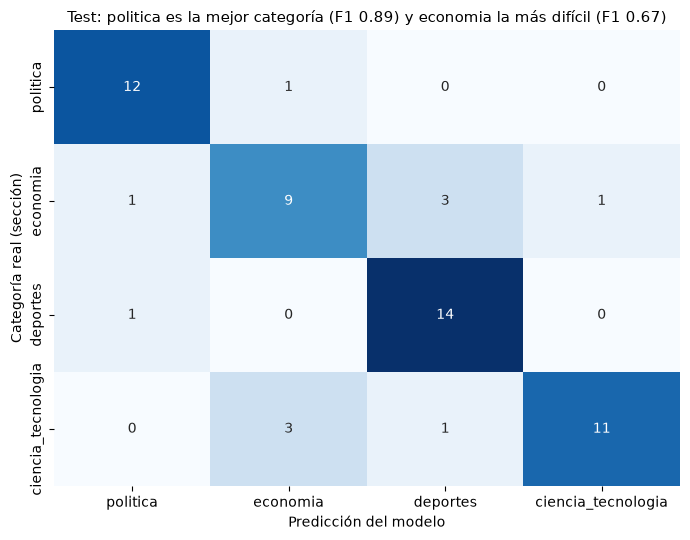

In [16]:
f1_cat = pd.Series(f1_score(test_df["etiqueta"], test_df["pred_ft"], labels=ETIQUETAS, average=None, zero_division=0),
                   index=ETIQUETAS)
cm = confusion_matrix(test_df["etiqueta"], test_df["pred_ft"], labels=ETIQUETAS)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=ETIQUETAS, yticklabels=ETIQUETAS, ax=ax)
ax.set_xlabel("Predicción del modelo")
ax.set_ylabel("Categoría real (sección)")
ax.set_title(f"Test: {f1_cat.idxmax()} es la mejor categoría (F1 {f1_cat.max():.2f}) "
             f"y {f1_cat.idxmin()} la más difícil (F1 {f1_cat.min():.2f})", fontsize=11)
plt.tight_layout()
plt.show()

In [17]:
errores = test_df[test_df["pred_ft"] != test_df["etiqueta"]]
print(f"Errores en test: {len(errores)} de {len(test_df)}")
errores[["titular", "etiqueta", "pred_ft", "seccion_original"]]

Errores en test: 11 de 57


,titular,etiqueta,pred_ft,seccion_original
82,Finlandia frena la construcción de dos centros de datos de Google por su impacto ambiental,ciencia_tecnologia,economia,tecnologia/actualidad
276,"El dólar abre en S/3,44 ante retroceso de la divisa estadounidense a nivel global",economia,deportes,economia/peru
189,Annia Cillóniz en su llegada al Cusco como líder de su categoría: “Las mujeres estamos demostrando que se ...,deportes,politica,deporte-total
197,"Ganadores del Premio Nobel de Economía: Hall, Woodford y su mirada microeconómica, ¿cuál es la importancia...",economia,ciencia_tecnologia,economia
299,Proyecto de Ley MAPE del gobierno propone que plantas de beneficio sean fiscalizadas ¿que otras medidas in...,politica,economia,politica/gobierno
260,Gobierno designa presidenta del directorio y directora ejecutiva del Fonafe,economia,politica,economia/peru
236,"El dólar abre al alza en S/3,44, pero retrocede ante mayor oferta local",economia,deportes,economia/peru
216,Rextie se prepara para su primer salto internacional: ¿a qué mercados mira la fintech de cambio de dólares...,economia,deportes,economia/peru
41,Perú: más de 200 operativos en el año en Madre de Dios no logran frenar el avance de la minería ilegal en ...,ciencia_tecnologia,economia,tecnologia/ecologia
52,"Francis Halzen, el nuevo premio nobel de Física, cuenta que usa la IA desde los 90: “Estoy muy orgulloso”",ciencia_tecnologia,deportes,tecnologia/inteligencia-artificial


### Reflexión por categoría

- **Mejor: `politica` (F1 0.89).** Sus titulares tienen un vocabulario muy propio y repetido: *Congreso, Senado, ministro, facultades, bancadas* y nombres de políticos. Además son los más largos (mediana de 109 caracteres frente a ~90 del resto, ver Parte 1), así que el modelo recibe más pistas. Solo falló en 1 de 13: el proyecto de *Ley MAPE*, que trata de regulación minera y usa vocabulario económico (*plantas de beneficio, fiscalización*).
- **`deportes` (F1 0.85)** recupera casi todo (14 de 15), pero atrae falsos positivos. Tres notas de economía se predijeron como deportes, dos de ellas del tipo *"El dólar abre en S/3,44…"*. La causa es lingüística: el modelo asocia las cifras con coma o guion a marcadores de partido (*"2-0"*, *"4-2"*), y como solo ve el titular, un número suelto lo empuja hacia deportes.
- **`ciencia_tecnologia` (F1 0.81)** falla en dos situaciones:
  - Cuando la nota tecnológica habla de empresas o de dinero, como los centros de datos de Google o Bill Gates.
  - Cuando cae en temas de frontera, como la minería ilegal en Madre de Dios, publicada en la subsección *ecología*.
- **Peor: `economia` (F1 0.67).** Es la categoría más transversal: comparte vocabulario con política (*"Gobierno designa… Fonafe"*), con tecnología (*fintech*, *Premio Nobel de Economía*) y, por las cifras, con deportes. Con ~63 ejemplos de entrenamiento, el modelo no alcanza a separar esos matices. En esta misma categoría el LLM logra F1 0.88, porque también lee la bajada y tiene conocimiento del mundo.

In [18]:
# Variante de supervisión débil: mismo modelo y partición, pero entrenado con las etiquetas del LLM
del trainer
gc.collect()
trainer_debil = entrenar("etiqueta_llm", str(MODELO / "_entrenamiento_debil"))
pred_debil = [id2label[i] for i in trainer_debil.predict(a_dataset(test_df)).predictions.argmax(-1)]
m_debil = metricas(test_df["etiqueta"], pred_debil)
print(f"DistilBERT entrenado con etiquetas del LLM -> TEST accuracy {m_debil['accuracy']:.3f} "
      f"| F1 macro {m_debil['f1_macro']:.3f}")
del trainer_debil
gc.collect();

Parámetros entrenables: 44 M de 135 M


{'loss': '1.229', 'grad_norm': '6.727', 'learning_rate': '3.431e-05', 'epoch': '1'}


{'eval_loss': '0.9569', 'eval_accuracy': '0.6786', 'eval_f1_macro': '0.5708', 'eval_runtime': '1.128', 'eval_samples_per_second': '49.66', 'eval_steps_per_second': '1.773', 'epoch': '1'}


{'loss': '0.7325', 'grad_norm': '6.194', 'learning_rate': '1.765e-05', 'epoch': '2'}


{'eval_loss': '0.6315', 'eval_accuracy': '0.7679', 'eval_f1_macro': '0.7049', 'eval_runtime': '1.207', 'eval_samples_per_second': '46.41', 'eval_steps_per_second': '1.657', 'epoch': '2'}


{'loss': '0.498', 'grad_norm': '5.845', 'learning_rate': '9.804e-07', 'epoch': '3'}


{'eval_loss': '0.552', 'eval_accuracy': '0.7679', 'eval_f1_macro': '0.7237', 'eval_runtime': '1.109', 'eval_samples_per_second': '50.48', 'eval_steps_per_second': '1.803', 'epoch': '3'}


{'train_runtime': '68.75', 'train_samples_per_second': '11.39', 'train_steps_per_second': '0.742', 'train_loss': '0.8198', 'epoch': '3'}
Entrenamiento: 69s


DistilBERT entrenado con etiquetas del LLM -> TEST accuracy 0.807 | F1 macro 0.796


## 6. Comparativa y decisión

Los cuatro enfoques se evalúan sobre **el mismo conjunto de test**, contra la etiqueta de sección. La latencia se midió en la misma laptop (CPU) y en milisegundos por titular.

In [19]:
zs = pipeline("zero-shot-classification", model=ZS_MODELO, device=-1)
t0 = time.time()
pred_zs_test = zero_shot(test_df["titular"])
lat_zs = (time.time() - t0) / len(test_df)
m_zs_test = metricas(test_df["etiqueta"], pred_zs_test)
m_llm_test = metricas(test_df["etiqueta"], test_df["etiqueta_llm"])
del zs
gc.collect()

comparativa = pd.DataFrame([
    {"enfoque": "Zero-shot BETO-XNLI", "entrenamiento": "ninguno", **m_zs_test,
     "latencia_ms": lat_zs * 1000, "tamaño_MB": 420},
    {"enfoque": "LLM Qwen2.5-1.5B (supervisión débil)", "entrenamiento": "ninguno (prompt)", **m_llm_test,
     "latencia_ms": lat_llm * 1000, "tamaño_MB": 1100},
    {"enfoque": "DistilBERT fine-tuned (etiquetas LLM)", "entrenamiento": "261 titulares", **m_debil,
     "latencia_ms": lat_ft * 1000, "tamaño_MB": 540},
    {"enfoque": "DistilBERT fine-tuned (sección)", "entrenamiento": "261 titulares", **m_ft,
     "latencia_ms": lat_ft * 1000, "tamaño_MB": 540},
])
comparativa.round({"accuracy": 3, "f1_macro": 3, "latencia_ms": 0})

,enfoque,entrenamiento,accuracy,f1_macro,latencia_ms,tamaño_MB
0,Zero-shot BETO-XNLI,ninguno,0.719,0.710,336.0,420
1,LLM Qwen2.5-1.5B (supervisión débil),ninguno (prompt),0.877,0.878,2695.0,1100
2,DistilBERT fine-tuned (etiquetas LLM),261 titulares,0.807,0.796,36.0,540
3,DistilBERT fine-tuned (sección),261 titulares,0.807,0.805,36.0,540


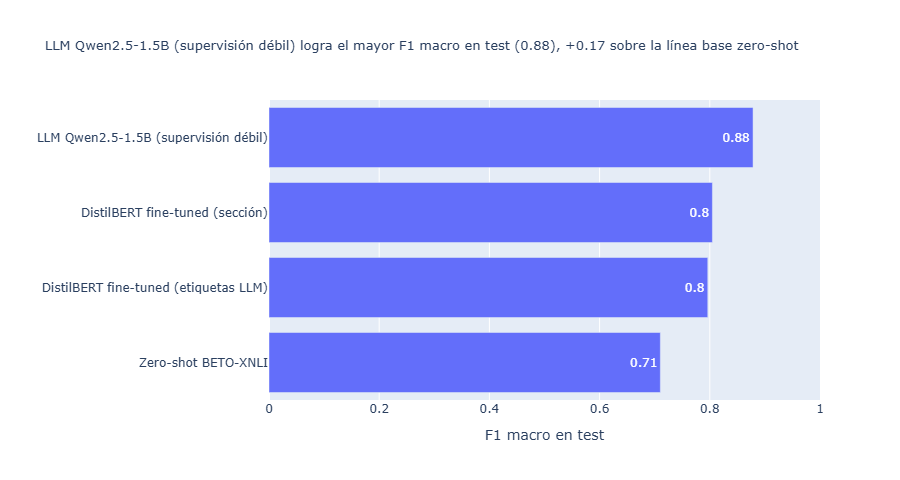

In [20]:
orden = comparativa.sort_values("f1_macro")
mejor, piso = orden.iloc[-1], comparativa.iloc[0]
fig = px.bar(
    orden, x="f1_macro", y="enfoque", orientation="h", text=orden["f1_macro"].round(2),
    title=(f"{mejor['enfoque']} logra el mayor F1 macro en test ({mejor['f1_macro']:.2f}), "
           f"{mejor['f1_macro'] - piso['f1_macro']:+.2f} sobre la línea base zero-shot"),
    labels={"f1_macro": "F1 macro en test", "enfoque": ""},
)
fig.update_layout(title_font_size=13, xaxis_range=[0, 1])
fig.show()

### Decisión para un entorno real

- **Precisión:** el LLM es el más preciso (F1 0.88), pero tiene ventaja de información: lee titular y bajada, mientras que DistilBERT solo ve el titular, que es lo que recibirá el dashboard. El zero-shot queda último (F1 0.71).
- **Costo y latencia (CPU):**
  - El LLM tarda ~2.7 s por noticia, ocupa 1.1 GB y necesita el runtime de `llama.cpp`.
  - DistilBERT responde en ~33 ms (unas **80 veces más rápido**), pesa 540 MB y se sirve con un `pipeline` estándar de `transformers`.
  - El zero-shot no compensa: es 9 veces más lento que DistilBERT y bastante menos preciso.
- **Hallazgo clave de la supervisión débil:** DistilBERT entrenado solo con las etiquetas del LLM obtiene en test casi el mismo F1 que el entrenado con la sección del diario (**0.80 vs. 0.805**). Es decir, las etiquetas del LLM bastan para entrenar sin etiquetar a mano.

**Decisión:** para el dashboard, y para un servicio real que clasifique titulares al instante, se elige **DistilBERT fine-tuned** (F1 0.80 en titulares nunca vistos, respuesta inmediata y barato de servir en CPU).

El LLM se reserva como **etiquetador offline**: como sus etiquetas débiles entrenan un modelo casi igual de bueno, sirve para ampliar el dataset a miles de titulares (más días y más medios) sin trabajo manual. Ese es el camino más directo para cerrar la brecha con el LLM, junto con entrenar con titular + bajada cuando el caso de uso lo permita.

Sobre la configuración: se respetaron las 3 épocas del enunciado y no se ajustó nada mirando el test. La mejor época según validación fue la 2 (F1 0.91 en validación frente a 0.805 en test). La diferencia es esperable con conjuntos de solo ~56 titulares, donde cada error mueve el F1 unos 2 puntos.

In [21]:
resultados = {
    "fecha_ejecucion": date.today().isoformat(),
    "n_noticias": int(len(df)),
    "n_test": int(len(test_df)),
    "f1_macro_test": round(m_ft["f1_macro"], 4),
    "accuracy_test": round(m_ft["accuracy"], 4),
    "zero_shot_f1_40": round(m_zs40["f1_macro"], 4),
    "zero_shot_accuracy_40": round(m_zs40["accuracy"], 4),
    "llm_f1_dataset": round(m_llm_total["f1_macro"], 4),
    "acuerdo_llm_humano": acuerdo,
    "modelo_llm": MODELO_LLM,
    "modelo_base": BASE,
    "comparativa": comparativa.round(4).to_dict(orient="records"),
}
(MODELO / "metricas.json").write_text(json.dumps(resultados, ensure_ascii=False, indent=2), encoding="utf-8")

acuerdo_txt = f"{acuerdo}/20" if acuerdo is not None else "pendiente/20"
print(f"Resultados Test: F1 Macro: {m_ft['f1_macro']:.2f} | Zero-shot: {m_zs40['f1_macro']:.2f} "
      f"| Acuerdo LLM-Humano: {acuerdo_txt}")

Resultados Test: F1 Macro: 0.80 | Zero-shot: 0.58 | Acuerdo LLM-Humano: 17/20
